<a href="https://colab.research.google.com/github/sakshigawade2808/Student-Performance-Prediction/blob/main/Student_Performance_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Student Performance and Behaviour.csv to Student Performance and Behaviour.csv


In [ ]:
df = pd.read_csv("/content/Student Performance and Behaviour.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
df.head()

,Student_ID,Semester_ID,Age,Gender,Region_Type,Family_Size,Major_Subject,University_Name,Home_City,Parent_Education,...,Attendance_Rate,Library_Visits_Per_Month,Extracurricular_Hours,Sleep_Hours,Social_Media_Usage_Hours,Stress_Level,Motivation_Score,Self_Efficacy_Score,Midterm_Mark,Final_Exam_Score
0,1,1,25,Male,Rural,2,Economics,Benha University,Qus,Secondary,...,73.5,8,1.4,6.8,2.5,9.5,7.3,5.82,54.3,5.6
1,2,7,18,Male,Urban,5,Architecture,Sadat Academy,Asyut,Diploma,...,70.5,4,1.1,6.0,1.4,4.6,4.2,4.41,53.8,45.7
2,3,6,28,Female,Urban,4,Data Science,Beni-Suef University,Abu Kabir,Bachelor,...,92.2,6,0.6,7.6,0.7,2.7,6.0,2.60,53.9,51.2
3,4,4,30,Female,Urban,4,Law,MSA University,Sohag,Secondary,...,71.4,7,8.4,7.8,2.6,6.6,4.5,1.36,38.4,41.0
4,5,4,22,Female,Urban,5,Biology,Zagazig University,Suez,Bachelor,...,89.5,10,10.7,5.5,0.8,6.3,8.3,5.00,55.6,65.8


In [ ]:
print("Shape of dataset:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Shape of dataset:
(500000, 27)

Columns:
['Student_ID', 'Semester_ID', 'Age', 'Gender', 'Region_Type', 'Family_Size', 'Major_Subject', 'University_Name', 'Home_City', 'Parent_Education', 'Family_Income_Level', 'Internet_Quality', 'Study_Space_Quality', 'Previous_GPA', 'Number_of_Failed_Courses', 'Total_Credits_Earned', 'Weekly_Study_Hours', 'Attendance_Rate', 'Library_Visits_Per_Month', 'Extracurricular_Hours', 'Sleep_Hours', 'Social_Media_Usage_Hours', 'Stress_Level', 'Motivation_Score', 'Self_Efficacy_Score', 'Midterm_Mark', 'Final_Exam_Score']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500000 entries, 0 to 499999
Data columns (total 27 columns):
 #   Column                    Non-Null Count   Dtype  
---  ------                    --------------   -----  
 0   Student_ID                500000 non-null  int64  
 1   Semester_ID               500000 non-null  int64  
 2   Age                       500000 non-null  int64  
 3   Gender                    500

In [ ]:
df.describe()

,Student_ID,Semester_ID,Age,Family_Size,Internet_Quality,Study_Space_Quality,Previous_GPA,Number_of_Failed_Courses,Total_Credits_Earned,Weekly_Study_Hours,Attendance_Rate,Library_Visits_Per_Month,Extracurricular_Hours,Sleep_Hours,Social_Media_Usage_Hours,Stress_Level,Motivation_Score,Self_Efficacy_Score,Midterm_Mark,Final_Exam_Score
count,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000,500000.000000
mean,250000.500000,4.500100,23.490706,5.002176,6.565998,6.453566,2.788552,1.334232,67.501920,18.160196,79.601553,9.224000,3.984422,6.800725,2.948750,5.520213,5.987168,4.539254,53.763787,57.570266
std,144337.711634,2.292028,4.026322,2.001290,2.187664,2.077266,0.674125,1.487346,35.840162,7.913285,13.194859,3.712289,3.972895,1.199408,2.778273,1.970166,1.947749,1.486886,10.395511,11.309997
min,1.000000,1.000000,17.000000,2.000000,1.000000,1.000000,0.000000,0.000000,12.000000,2.000000,0.000000,0.000000,0.000000,3.000000,0.000000,1.000000,1.000000,1.000000,0.000000,0.000000
25%,125000.750000,2.000000,20.000000,3.000000,5.100000,5.000000,2.330000,0.000000,36.000000,12.700000,72.600000,7.000000,1.100000,6.000000,0.900000,4.200000,4.600000,3.520000,46.800000,50.400000
50%,250000.500000,5.000000,23.000000,5.000000,6.700000,6.500000,2.800000,1.000000,68.000000,18.100000,81.900000,9.000000,2.800000,6.800000,2.100000,5.500000,6.000000,4.540000,53.600000,57.600000
75%,375000.250000,6.000000,27.000000,7.000000,8.200000,8.000000,3.270000,2.000000,96.000000,23.500000,89.200000,12.000000,5.500000,7.600000,4.200000,6.900000,7.400000,5.550000,60.500000,64.800000
max,500000.000000,8.000000,30.000000,8.000000,10.000000,10.000000,4.000000,10.000000,144.000000,40.000000,100.000000,24.000000,30.000000,11.000000,12.000000,10.000000,10.000000,10.000000,100.000000,100.000000


In [ ]:
df.isnull().sum()

,0
Student_ID,0
Semester_ID,0
Age,0
Gender,0
Region_Type,0
Family_Size,0
Major_Subject,0
University_Name,0
Home_City,0
Parent_Education,0


In [ ]:
missing_percentage = (df.isnull().sum() / len(df)) * 100

print(missing_percentage)

Student_ID                  0.0
Semester_ID                 0.0
Age                         0.0
Gender                      0.0
Region_Type                 0.0
Family_Size                 0.0
Major_Subject               0.0
University_Name             0.0
Home_City                   0.0
Parent_Education            0.0
Family_Income_Level         0.0
Internet_Quality            0.0
Study_Space_Quality         0.0
Previous_GPA                0.0
Number_of_Failed_Courses    0.0
Total_Credits_Earned        0.0
Weekly_Study_Hours          0.0
Attendance_Rate             0.0
Library_Visits_Per_Month    0.0
Extracurricular_Hours       0.0
Sleep_Hours                 0.0
Social_Media_Usage_Hours    0.0
Stress_Level                0.0
Motivation_Score            0.0
Self_Efficacy_Score         0.0
Midterm_Mark                0.0
Final_Exam_Score            0.0
dtype: float64


In [ ]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [ ]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)

Shape after removing duplicates: (500000, 27)


In [ ]:
print(df["Final_Exam_Score"].describe())

count    500000.000000
mean         57.570266
std          11.309997
min           0.000000
25%          50.400000
50%          57.600000
75%          64.800000
max         100.000000
Name: Final_Exam_Score, dtype: float64


In [ ]:
df.columns

Index(['Student_ID', 'Semester_ID', 'Age', 'Gender', 'Region_Type',
       'Family_Size', 'Major_Subject', 'University_Name', 'Home_City',
       'Parent_Education', 'Family_Income_Level', 'Internet_Quality',
       'Study_Space_Quality', 'Previous_GPA', 'Number_of_Failed_Courses',
       'Total_Credits_Earned', 'Weekly_Study_Hours', 'Attendance_Rate',
       'Library_Visits_Per_Month', 'Extracurricular_Hours', 'Sleep_Hours',
       'Social_Media_Usage_Hours', 'Stress_Level', 'Motivation_Score',
       'Self_Efficacy_Score', 'Midterm_Mark', 'Final_Exam_Score'],
      dtype='object')

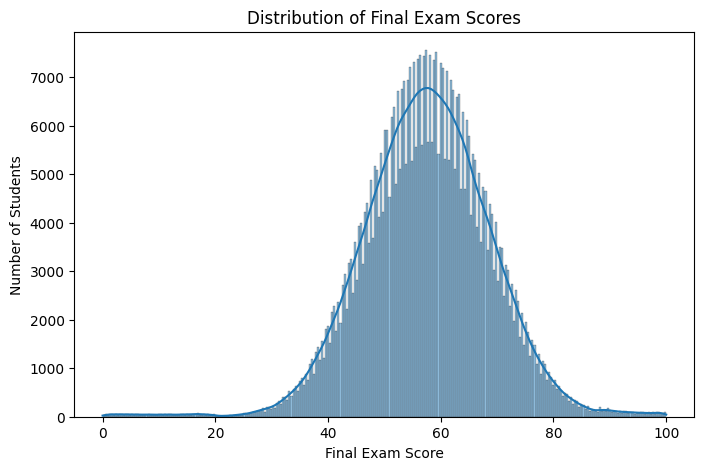

In [ ]:
plt.figure(figsize=(8,5))

sns.histplot(df["Final_Exam_Score"], kde=True)

plt.title("Distribution of Final Exam Scores")
plt.xlabel("Final Exam Score")
plt.ylabel("Number of Students")

plt.show()

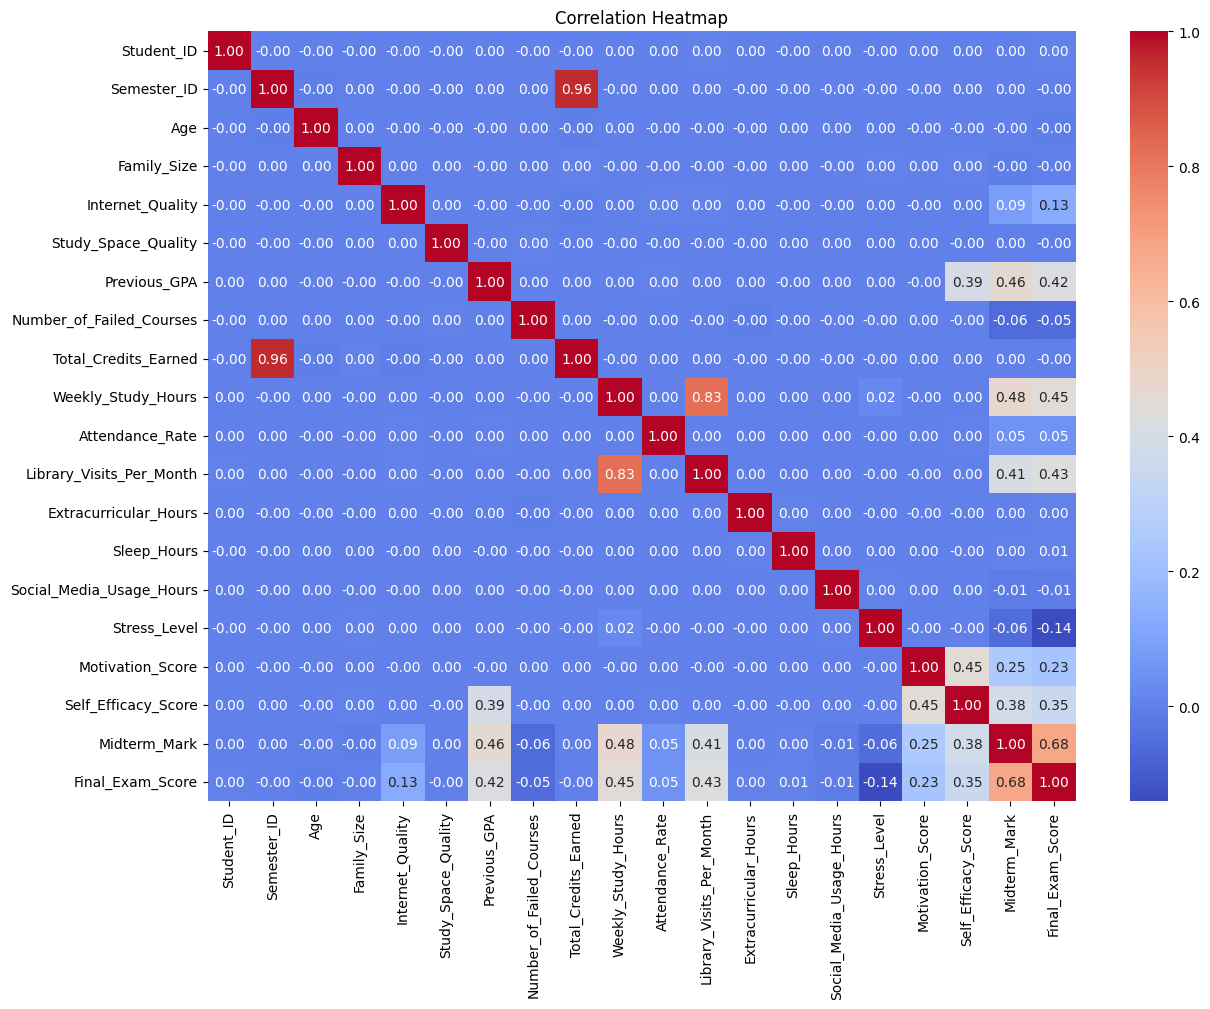

In [ ]:
plt.figure(figsize=(14,10))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

In [ ]:
X = df.drop(
    [
        "Student_ID",
        "Semester_ID",
        "University_Name",
        "Home_City",
        "Final_Exam_Score"

    ],
    axis=1
)

y = df["Final_Exam_Score"]

print("Feature columns:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Feature columns:
['Age', 'Gender', 'Region_Type', 'Family_Size', 'Major_Subject', 'Parent_Education', 'Family_Income_Level', 'Internet_Quality', 'Study_Space_Quality', 'Previous_GPA', 'Number_of_Failed_Courses', 'Total_Credits_Earned', 'Weekly_Study_Hours', 'Attendance_Rate', 'Library_Visits_Per_Month', 'Extracurricular_Hours', 'Sleep_Hours', 'Social_Media_Usage_Hours', 'Stress_Level', 'Motivation_Score', 'Self_Efficacy_Score', 'Midterm_Mark']

Target:
Final_Exam_Score


In [ ]:
numerical_features = [
    "Age",
    "Family_Size",
    "Previous_GPA",
    "Number_of_Failed_Courses",
    "Total_Credits_Earned",
    "Weekly_Study_Hours",
    "Attendance_Rate",
    "Library_Visits_Per_Month",
    "Extracurricular_Hours",
    "Sleep_Hours",
    "Social_Media_Usage_Hours",
    "Stress_Level",
    "Motivation_Score",
    "Self_Efficacy_Score",
    "Midterm_Mark"
]

categorical_features = [
    "Gender",
    "Region_Type",
    "Major_Subject",
    "Parent_Education",
    "Family_Income_Level",
    "Internet_Quality",
    "Study_Space_Quality"
]

print("Numerical features:", len(numerical_features))
print("Categorical features:", len(categorical_features))
print("Total features:", len(numerical_features) + len(categorical_features))

Numerical features: 15
Categorical features: 7
Total features: 22


In [ ]:
print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print(y.name)

Features:
['Age', 'Gender', 'Region_Type', 'Family_Size', 'Major_Subject', 'Parent_Education', 'Family_Income_Level', 'Internet_Quality', 'Study_Space_Quality', 'Previous_GPA', 'Number_of_Failed_Courses', 'Total_Credits_Earned', 'Weekly_Study_Hours', 'Attendance_Rate', 'Library_Visits_Per_Month', 'Extracurricular_Hours', 'Sleep_Hours', 'Social_Media_Usage_Hours', 'Stress_Level', 'Motivation_Score', 'Self_Efficacy_Score', 'Midterm_Mark']

Target:
Final_Exam_Score


In [ ]:
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist()

In [ ]:
print("Numerical Features:")
print(numeric_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Age', 'Family_Size', 'Internet_Quality', 'Study_Space_Quality', 'Previous_GPA', 'Number_of_Failed_Courses', 'Total_Credits_Earned', 'Weekly_Study_Hours', 'Attendance_Rate', 'Library_Visits_Per_Month', 'Extracurricular_Hours', 'Sleep_Hours', 'Social_Media_Usage_Hours', 'Stress_Level', 'Motivation_Score', 'Self_Efficacy_Score', 'Midterm_Mark']

Categorical Features:
['Gender', 'Region_Type', 'Major_Subject', 'Parent_Education', 'Family_Income_Level']


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

In [ ]:
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (400000, 22)
Testing data: (100000, 22)


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numerical_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
          n_estimators=30,
        n_jobs=-1,
        random_state=42
    ))
])

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [ ]:
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500000, 22)
y shape: (500000,)


In [ ]:
rf_model.fit(X,y)
print("Corrected model trained successfully!")

Corrected model trained successfully!


In [ ]:
import joblib

joblib.dump(rf_model, "student_performance_model_v2.pkl")

print("Model saved successfully!")

Model saved successfully!


In [ ]:
print("Numeric features:")
print(numeric_features)

print("\nCategorical features:")
print(categorical_features)

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)
linear_model.fit(X_train, y_train)
y_pred_linear = linear_model.predict(X_test)

In [ ]:
#decision tree
tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", DecisionTreeRegressor(
            random_state=42,
            max_depth=10
        ))
    ]
)
tree_model.fit(X_train, y_train)
y_pred_tree = tree_model.predict(X_test)

In [ ]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=50,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

In [ ]:
rf_model.fit(X_train, y_train)

In [ ]:
new_student = pd.DataFrame({
    "Age": [20],
    "Gender": ["Male"],
    "Region_Type": ["Urban"],
    "Family_Size": [4],
    "Major_Subject": ["Computer Science"],
    "Parent_Education": ["Graduate"],
    "Family_Income_Level": ["Medium"],

    # These two must be NUMERIC
    "Internet_Quality": [8],
    "Study_Space_Quality": [8],

    "Previous_GPA": [3.2],
    "Number_of_Failed_Courses": [0],
    "Total_Credits_Earned": [80],
    "Weekly_Study_Hours": [20],
    "Attendance_Rate": [85],
    "Library_Visits_Per_Month": [5],
    "Extracurricular_Hours": [3],
    "Sleep_Hours": [7],
    "Social_Media_Usage_Hours": [2],
    "Stress_Level": [4],
    "Motivation_Score": [8],
    "Self_Efficacy_Score": [8],
    "Midterm_Mark": [78]
})

print(new_student)
print("\nData types:")
print(new_student.dtypes)

   Age Gender Region_Type  Family_Size     Major_Subject Parent_Education  \
0   20   Male       Urban            4  Computer Science         Graduate   

  Family_Income_Level  Internet_Quality  Study_Space_Quality  Previous_GPA  \
0              Medium                 8                    8           3.2   

   ...  Weekly_Study_Hours  Attendance_Rate  Library_Visits_Per_Month  \
0  ...                  20               85                         5   

   Extracurricular_Hours  Sleep_Hours  Social_Media_Usage_Hours  Stress_Level  \
0                      3            7                         2             4   

   Motivation_Score  Self_Efficacy_Score  Midterm_Mark  
0                 8                    8            78  

[1 rows x 22 columns]

Data types:
Age                           int64
Gender                       object
Region_Type                  object
Family_Size                   int64
Major_Subject                object
Parent_Education             object
Family_Incom

In [ ]:
predicted_score = rf_model.predict(new_student)

print("Predicted Final Exam Score:", predicted_score[0])

Predicted Final Exam Score: 68.59


In [ ]:
#Evaluate model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)
def evaluate_model(y_test, y_pred, model_name):

    mae = mean_absolute_error(y_test, y_pred)

    mse = mean_squared_error(y_test, y_pred)

    rmse = np.sqrt(mse)

    r2 = r2_score(y_test, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [ ]:
y_pred_rf = rf_model.predict(X_test)
results = []

results.append(
    evaluate_model(
        y_test,
        y_pred_linear,
        "Linear Regression"
    )
)

results.append(
    evaluate_model(
        y_test,
        y_pred_tree,
        "Decision Tree"
    )
)

results.append(
    evaluate_model(
        y_test,
        y_pred_rf,
        "Random Forest"
    )
)
y_pred_linear

NameError: name 'rf_model' is not defined

In [ ]:
results_df = pd.DataFrame(results)

results_df

In [ ]:
results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10,6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Error")
plt.xticks(rotation=0)

plt.show()

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    results_df["Model"],
    results_df["R2 Score"]
)

plt.title("R² Score Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.xticks(rotation=15)

plt.show()

In [ ]:
plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred_rf,
    alpha=0.5
)

plt.xlabel("Actual Final Exam Score")
plt.ylabel("Predicted Final Exam Score")

plt.title("Actual vs Predicted Final Exam Scores")

plt.show()

In [ ]:
rf_preprocessor = rf_model.named_steps["preprocessor"]

rf_regressor = rf_model.named_steps["model"]

In [ ]:
feature_names = rf_preprocessor.get_feature_names_out()

In [ ]:
importance = rf_regressor.feature_importances_

In [ ]:
feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

In [ ]:
feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

In [ ]:
feature_importance_df.head(15)

In [ ]:
top_features = feature_importance_df.head(15)

plt.figure(figsize=(10,7))

plt.barh(
    top_features["Feature"][::-1],
    top_features["Importance"][::-1]
)

plt.xlabel("Importance")
plt.ylabel("Features")

plt.title("Top 15 Important Features")

plt.show()

In [ ]:
'''new_student = pd.DataFrame({
    "Age": [20],
    "Gender": ["Male"],
    "Region_Type": ["Urban"],
    "Family_Size": [4],
    "Major_Subject": ["Computer Science"],
    "Parent_Education": ["Graduate"],
    "Family_Income_Level": ["Medium"],
    "Internet_Quality": ["Good"],
    "Study_Space_Quality": ["Good"],
    "Previous_GPA": [8.2],
    "Number_of_Failed_Courses": [0],
    "Total_Credits_Earned": [80],
    "Weekly_Study_Hours": [20],
    "Attendance_Rate": [85],
    "Library_Visits_Per_Month": [5],
    "Extracurricular_Hours": [3],
    "Sleep_Hours": [7],
    "Social_Media_Usage_Hours": [2],
    "Stress_Level": [4],
    "Motivation_Score": [8],
    "Self_Efficacy_Score": [8],
    "Midterm_Mark": [78]
})'''

In [ ]:
predicted_score = rf_model.predict(new_student)

print("Predicted Final Exam Score:", predicted_score[0])

In [ ]:
y_pred_rf = rf_model.predict(X_test)

evaluate_model(
    y_test,
    y_pred_rf,
    "Random Forest"
)

In [ ]:
# Display variables containing model names
%whos

In [ ]:
results_df

In [ ]:
results_df.sort_values(by="R2 Score", ascending=False)

In [ ]:
top_features.head(10)

In [ ]:
plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"].head(10)[::-1],
    top_features["Importance"].head(10)[::-1]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top 10 Features Influencing Student Performance")
plt.show()

In [ ]:
predicted_score = rf_model.predict(new_student)

print("Predicted Final Exam Score:", predicted_score[0])

In [ ]:
score = predicted_score[0]

if score >= 75:
    performance = "Excellent"
elif score >= 60:
    performance = "Good"
elif score >= 40:
    performance = "Average"
else:
    performance = "Needs Improvement"

print("Predicted Final Exam Score:", round(score, 2))
print("Performance Level:", performance)

In [ ]:
import joblib

joblib.dump(rf_model, "student_performance_random_forest.pkl")

print("Model saved successfully!")

In [ ]:
import os

print(os.path.exists("student_performance_random_forest.pkl"))

In [ ]:
from google.colab import files

files.download("/content/student_performance_random_forest.pkl")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copy(
    "/content/student_performance_random_forest.pkl",
    "/content/drive/MyDrive/student_performance_random_forest.pkl"
)

In [ ]:
import os

print(os.path.exists(
    "/content/drive/MyDrive/student_performance_random_forest.pkl"
))

In [ ]:
#new model
import shutil

shutil.copy(
    "student_performance_model_v2.pkl",
    "/content/drive/MyDrive/student_performance_model_v2.pkl"
)

print("Model copied to Google Drive successfully!")

Model copied to Google Drive successfully!
